In [1]:

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import pearsonr, spearmanr

CITY = "Chennai"

PROJECT_DIR = Path.cwd().parent
DATA_DIR = PROJECT_DIR / "data" / "regions"
OUTPUT_DIR = PROJECT_DIR / f"series2_outputs/{CITY.lower()}"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

data = pd.read_csv(DATA_DIR / f"{CITY}_cell_year_2015_2025.csv")

data["year"] = pd.to_numeric(data["year"], errors="coerce")

VARIABLES = ["lst_c", "ndbi", "ndvi"]
YEARS = list(range(2015, 2026))
MAP_YEARS = [2015, 2020, 2025]

sns.set_theme(style="whitegrid")

print(f"City: {CITY}")
print(f"Records: {len(data):,}")
print(f"Unique grid cells: {data['grid_id'].nunique():,}")
print(f"Years present: {sorted(data['year'].dropna().unique().astype(int))}")
print(f"Output directory: {OUTPUT_DIR}")
display(data.head())


City: Chennai
Records: 50,996
Unique grid cells: 4,636
Years present: [np.int64(2015), np.int64(2016), np.int64(2017), np.int64(2018), np.int64(2019), np.int64(2020), np.int64(2021), np.int64(2022), np.int64(2023), np.int64(2024), np.int64(2025)]
Output directory: d:\sparkle\urban heat lockin\series2_outputs\chennai


,grid_id,city_id,city,year,lst_c,ndvi,ndbi,n_obs_mean,l8_scenes,l9_scenes,sensor_mix
0,Chennai_25770_5491,Chennai,Chennai,2015,42.616588,0.358428,-0.015893,3.925302,7,0,Landsat 8
1,Chennai_25770_5491,Chennai,Chennai,2016,44.129162,0.390138,-0.036147,3.126079,8,0,Landsat 8
2,Chennai_25770_5491,Chennai,Chennai,2017,41.630354,0.339333,-0.007966,4.814335,8,0,Landsat 8
3,Chennai_25770_5491,Chennai,Chennai,2018,34.718208,0.365150,-0.027451,2.039724,7,0,Landsat 8
4,Chennai_25770_5491,Chennai,Chennai,2019,45.791191,0.334499,0.007622,4.000000,7,0,Landsat 8


,records,unique_cells,mean_observations
year,,,
2015,4636,4636,3.861444
2016,4636,4636,4.901926
2017,4636,4636,4.367770
2018,4636,4636,3.620941
2019,4636,4636,3.975687
2020,4636,4636,4.215289
2021,4636,4636,4.639140
2022,4636,4636,5.972340
2023,4636,4636,7.334994


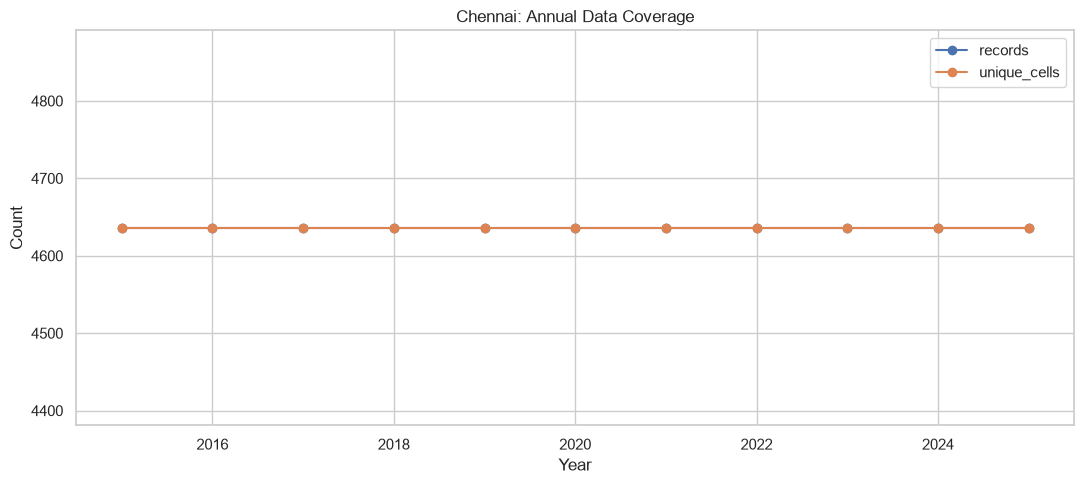

,missing_count,missing_percent
lst_c,0,0.000000
ndbi,1,0.001961
ndvi,1,0.001961
n_obs_mean,0,0.000000


In [2]:

# Number of records and unique grid cells per year
year_coverage = (
    data.groupby("year")
    .agg(
        records=("grid_id", "size"),
        unique_cells=("grid_id", "nunique"),
        mean_observations=("n_obs_mean", "mean")
    )
    .reindex(YEARS)
)

display(year_coverage)

ax = year_coverage[["records", "unique_cells"]].plot(
    figsize=(11, 5), marker="o"
)
ax.set_title(f"{CITY}: Annual Data Coverage")
ax.set_xlabel("Year")
ax.set_ylabel("Count")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "01_annual_coverage.png", dpi=200)
plt.show()

# Missing values
missing = data[VARIABLES + ["n_obs_mean"]].isna().sum().to_frame("missing_count")
missing["missing_percent"] = missing["missing_count"] / len(data) * 100
display(missing)

missing.to_csv(OUTPUT_DIR / "missing_values.csv")


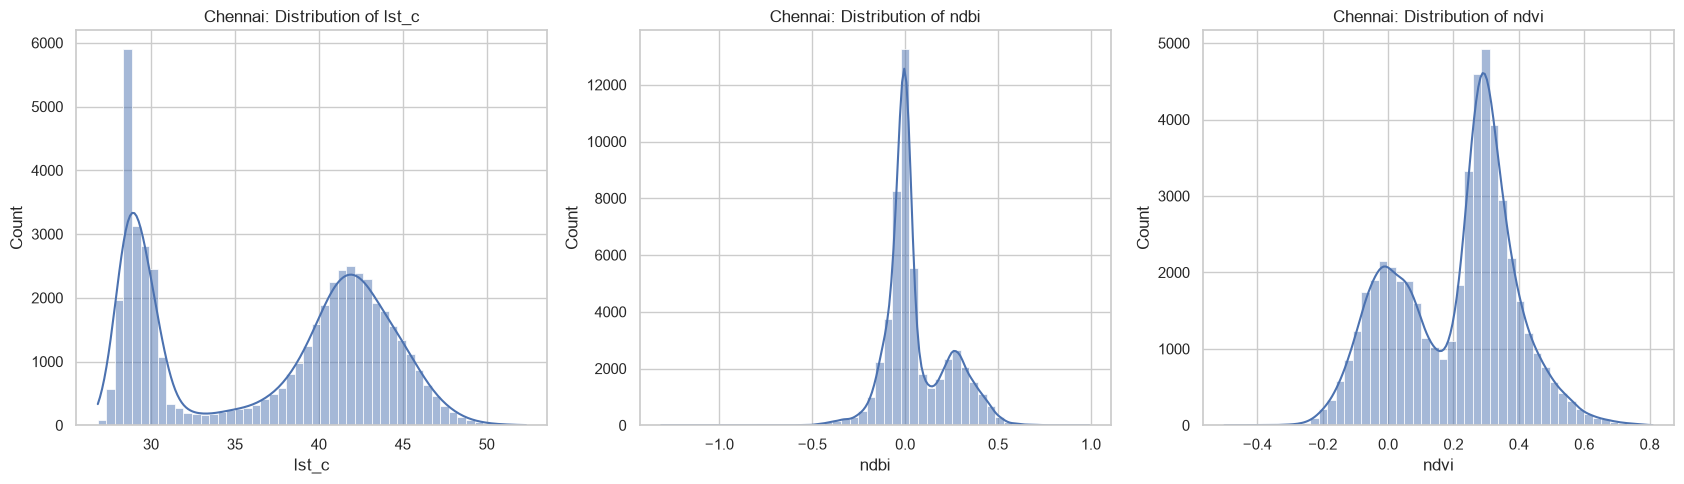

,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,max
lst_c,50996.0,37.173592,6.565832,26.832251,27.779556,28.352051,29.552479,39.724928,42.661332,45.857973,47.828135,52.338659
ndbi,50995.0,0.055820,0.167610,-1.313442,-0.308148,-0.154614,-0.039368,0.007093,0.152698,0.382580,0.485283,0.991259
ndvi,50995.0,0.205332,0.182675,-0.500337,-0.173267,-0.098512,0.044744,0.256403,0.329804,0.474160,0.589125,0.809234


In [3]:

fig, axes = plt.subplots(1, 3, figsize=(17, 5))

for ax, variable in zip(axes, VARIABLES):
    sns.histplot(
        data=data,
        x=variable,
        bins=50,
        kde=True,
        ax=ax
    )
    ax.set_title(f"{CITY}: Distribution of {variable}")
    ax.set_xlabel(variable)

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "02_variable_distributions.png", dpi=200)
plt.show()

display(data[VARIABLES].describe(percentiles=[
    0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99
]).T)


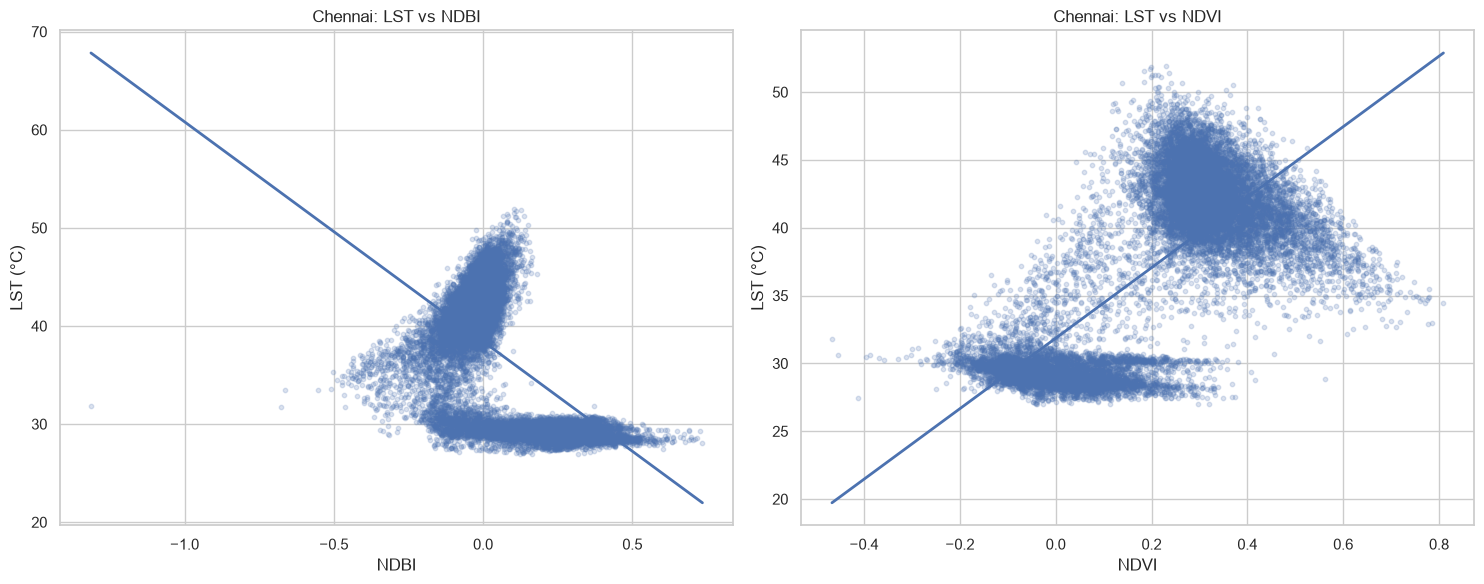

In [4]:

plot_data = data.dropna(subset=["lst_c", "ndbi", "ndvi"]).copy()

plot_sample = plot_data.sample(
    n=min(20000, len(plot_data)),
    random_state=42
)

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

for ax, xvar, title in [
    (axes[0], "ndbi", "LST vs NDBI"),
    (axes[1], "ndvi", "LST vs NDVI")
]:
    sns.regplot(
        data=plot_sample,
        x=xvar,
        y="lst_c",
        ax=ax,
        scatter_kws={"alpha": 0.2, "s": 10},
        line_kws={"linewidth": 2},
        ci=None
    )
    ax.set_title(f"{CITY}: {title}")
    ax.set_xlabel(xvar.upper())
    ax.set_ylabel("LST (°C)")

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "03_lst_relationships.png", dpi=200)
plt.show()


In [5]:

PAIRS = [
    ("lst_c", "ndbi"),
    ("lst_c", "ndvi"),
    ("ndbi", "ndvi")
]

def calculate_correlations(df):
    results = []

    for x, y in PAIRS:
        pair = df[[x, y]].replace([np.inf, -np.inf], np.nan).dropna()
        n = len(pair)

        result = {
            "variable_1": x,
            "variable_2": y,
            "n": n,
            "pearson_r": np.nan,
            "pearson_p": np.nan,
            "spearman_rho": np.nan,
            "spearman_p": np.nan
        }

        if n >= 3 and pair[x].nunique() > 1 and pair[y].nunique() > 1:
            r, p = pearsonr(pair[x], pair[y])
            rho, sp = spearmanr(pair[x], pair[y])

            result.update({
                "pearson_r": r,
                "pearson_p": p,
                "spearman_rho": rho,
                "spearman_p": sp
            })

        results.append(result)

    return pd.DataFrame(results)

pooled_corr = calculate_correlations(data)
display(pooled_corr)
pooled_corr.to_csv(OUTPUT_DIR / "pooled_correlations.csv", index=False)

annual_corr = pd.concat(
    [
        calculate_correlations(group).assign(year=int(year))
        for year, group in data.groupby("year")
    ],
    ignore_index=True
)

display(annual_corr)
annual_corr.to_csv(OUTPUT_DIR / "annual_correlations.csv", index=False)


,variable_1,variable_2,n,pearson_r,pearson_p,spearman_rho,spearman_p
0,lst_c,ndbi,50995,-0.569960,0.0,-0.405428,0.0
1,lst_c,ndvi,50995,0.724134,0.0,0.598908,0.0
2,ndbi,ndvi,50995,-0.534697,0.0,-0.574584,0.0


,variable_1,variable_2,n,pearson_r,pearson_p,spearman_rho,spearman_p,year
0,lst_c,ndbi,4636,-0.612376,0.000000e+00,-0.445865,2.466917e-225,2015
1,lst_c,ndvi,4636,0.661387,0.000000e+00,0.554518,0.000000e+00,2015
2,ndbi,ndvi,4636,-0.486725,2.094190e-274,-0.621462,0.000000e+00,2015
3,lst_c,ndbi,4636,-0.608767,0.000000e+00,-0.396515,2.215388e-174,2016
4,lst_c,ndvi,4636,0.843112,0.000000e+00,0.609577,0.000000e+00,2016
5,ndbi,ndvi,4636,-0.628267,0.000000e+00,-0.594332,0.000000e+00,2016
6,lst_c,ndbi,4636,-0.638190,0.000000e+00,-0.443138,2.725823e-222,2017
7,lst_c,ndvi,4636,0.789828,0.000000e+00,0.625843,0.000000e+00,2017
8,ndbi,ndvi,4636,-0.583129,0.000000e+00,-0.566382,0.000000e+00,2017
9,lst_c,ndbi,4635,-0.491363,2.386175e-280,-0.314268,8.988636e-107,2018


lst_c                                 ndbi                      \
           mean     median       std count      mean    median       std   
year                                                                       
2015  37.254107  39.541309  5.756226  4636  0.052712  0.006114  0.155465   
2016  37.576596  40.585115  6.214839  4636  0.052249 -0.010778  0.182099   
2017  36.926706  40.049973  6.385247  4636  0.082435  0.031690  0.144831   
2018  35.577598  38.074655  6.074031  4636  0.045562  0.006280  0.147896   
2019  38.871517  43.404294  7.925049  4636  0.048683  0.026532  0.121323   
2020  37.988321  41.338944  6.779463  4636  0.042670  0.007394  0.166276   
2021  36.232820  38.293746  5.419619  4636  0.043107  0.002198  0.159600   
2022  38.724981  42.658088  7.558148  4636  0.025824 -0.004204  0.130492   
2023  36.790800  39.827338  6.528230  4636  0.065907 -0.005784  0.205995   
2024  36.579597  39.875393  6.342732  4636  0.088655  0.010634  0.195636   
2025  36.386468  39.209576  6.002566  4636  0.066214 -0.007348  0.199803   

                ndvi                            
     count      mean    median       std count  
year                                            
2015  4636  0.227316  0.280601  0.183030  4636  
2016  4636  0.171456  0.269235  0.227576  4636  
2017  4636  0.179135  0.225944  0.148215  4636  
2018  4635  0.208002  0.253101  0.159031  4635  
2019  4636  0.174035  0.236299  0.174951  4636  
2020  4636  0.195761  0.269298  0.204009  4636  
2021  4636  0.236058  0.276048  0.166720  4636  
2022  4636  0.211404  0.262468  0.167893  4636  
2023  4636  0.225387  0.271062  0.178660  4636  
2024  4636  0.205890  0.250802  0.178832  4636  
2025  4636  0.224211  0.272235  0.193249  4636

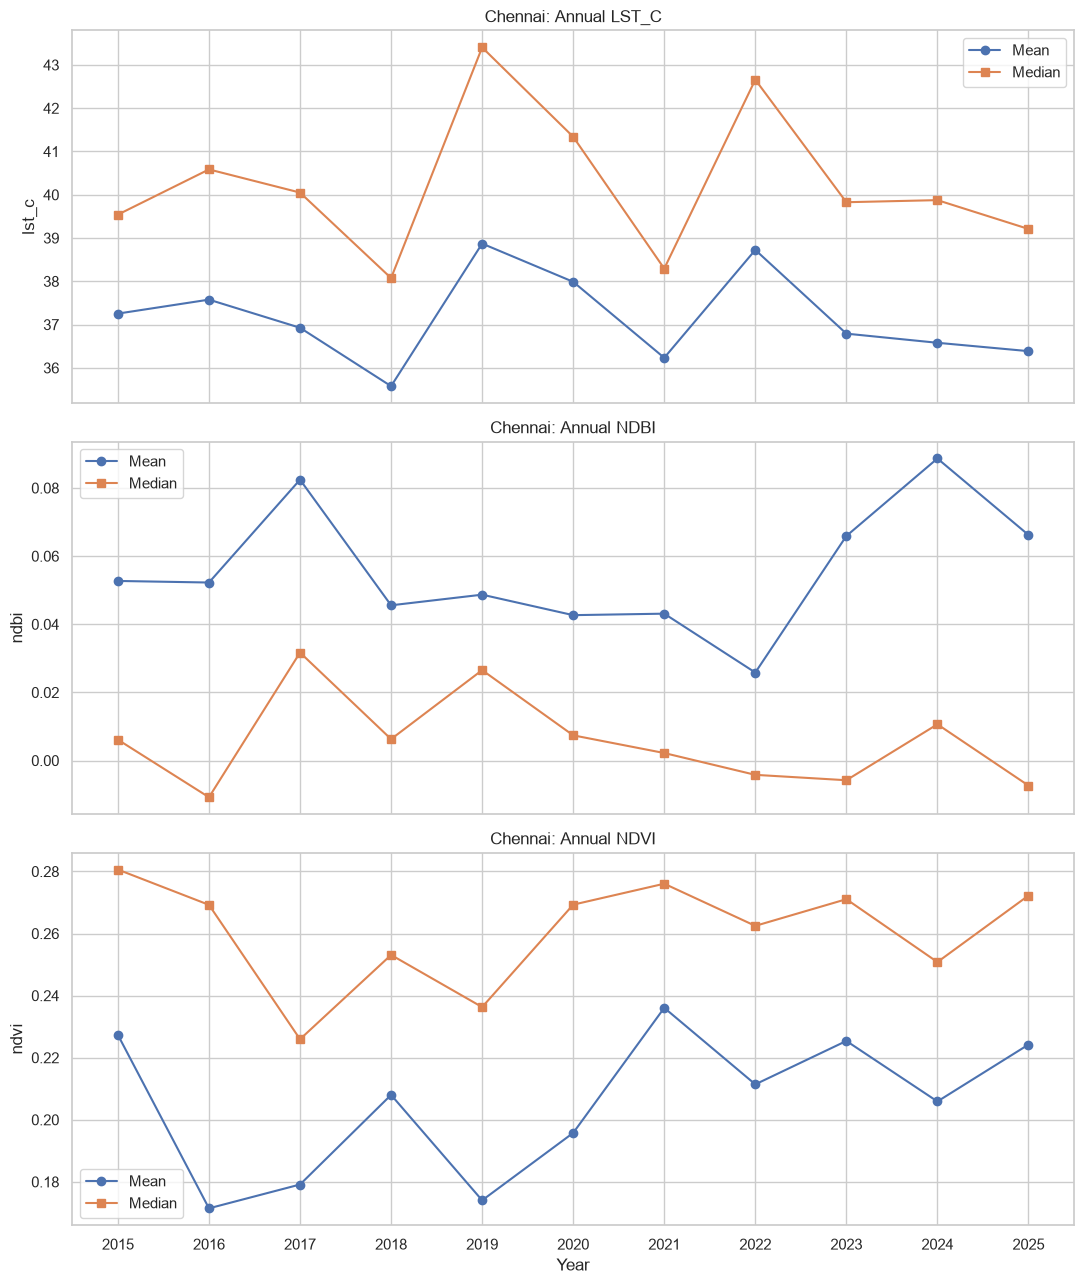

In [6]:

annual_stats = (
    data.groupby("year")[VARIABLES]
    .agg(["mean", "median", "std", "count"])
    .reindex(YEARS)
)

display(annual_stats)
annual_stats.to_csv(OUTPUT_DIR / "annual_summary_statistics.csv")

fig, axes = plt.subplots(3, 1, figsize=(11, 13), sharex=True)

for ax, variable in zip(axes, VARIABLES):
    stats = data.groupby("year")[variable].agg(["mean", "median"])

    ax.plot(stats.index, stats["mean"], marker="o", label="Mean")
    ax.plot(stats.index, stats["median"], marker="s", label="Median")

    ax.set_title(f"{CITY}: Annual {variable.upper()}")
    ax.set_ylabel(variable)
    ax.legend()

axes[-1].set_xlabel("Year")
axes[-1].set_xticks(YEARS)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "04_annual_trends.png", dpi=200)
plt.show()


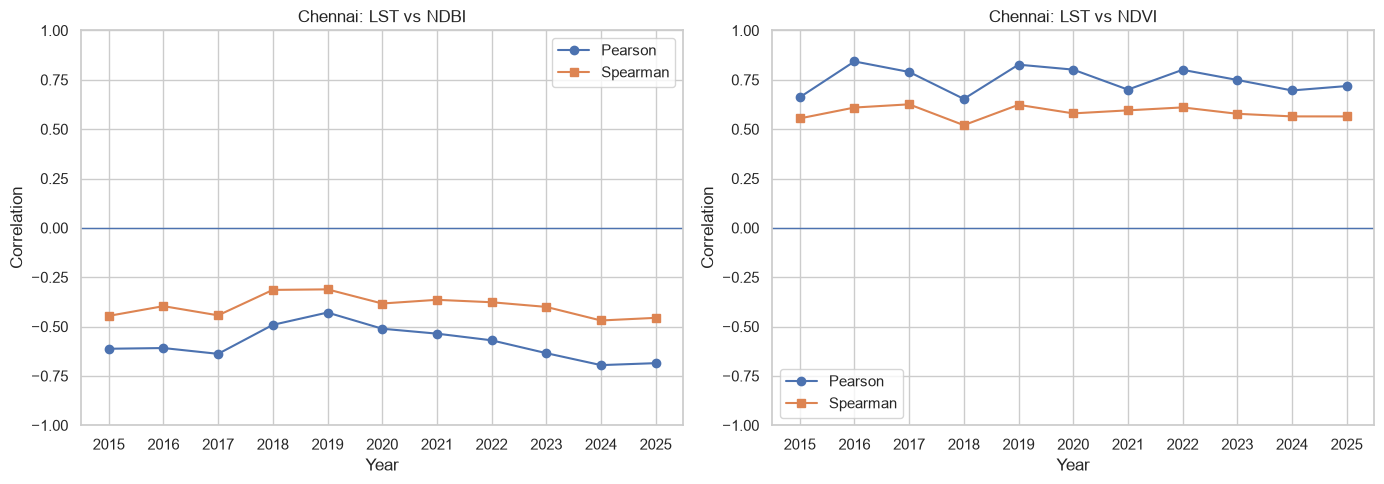

In [7]:

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, xvar, title in [
    (axes[0], "ndbi", "LST vs NDBI"),
    (axes[1], "ndvi", "LST vs NDVI")
]:
    subset = annual_corr[
        (annual_corr["variable_1"] == "lst_c") &
        (annual_corr["variable_2"] == xvar)
    ]

    ax.plot(
        subset["year"], subset["pearson_r"],
        marker="o", label="Pearson"
    )
    ax.plot(
        subset["year"], subset["spearman_rho"],
        marker="s", label="Spearman"
    )
    ax.axhline(0, linewidth=1)
    ax.set_title(f"{CITY}: {title}")
    ax.set_xlabel("Year")
    ax.set_ylabel("Correlation")
    ax.set_ylim(-1, 1)
    ax.set_xticks(YEARS)
    ax.legend()

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "05_annual_correlations.png", dpi=200)
plt.show()


Grid columns: ['grid_id', 'in_frac', 'city_id', 'geometry']
Grid CRS: PROJCS["WGS 84 / World Cylindrical Equal Area",GEOGCS["WGS 84",DATUM["WGS_1984",SPHEROID["WGS 84",6378137,298.257223563]],PRIMEM["Greenwich",0],UNIT["degree",0.0174532925199433]],PROJECTION["Cylindrical_Equal_Area"],PARAMETER["central_meridian",0],PARAMETER["standard_parallel_1",30],PARAMETER["false_easting",0],PARAMETER["false_northing",0],UNIT["m",1],AXIS["X",EAST],AXIS["Y",NORTH]]
Number of grid cells: 4636


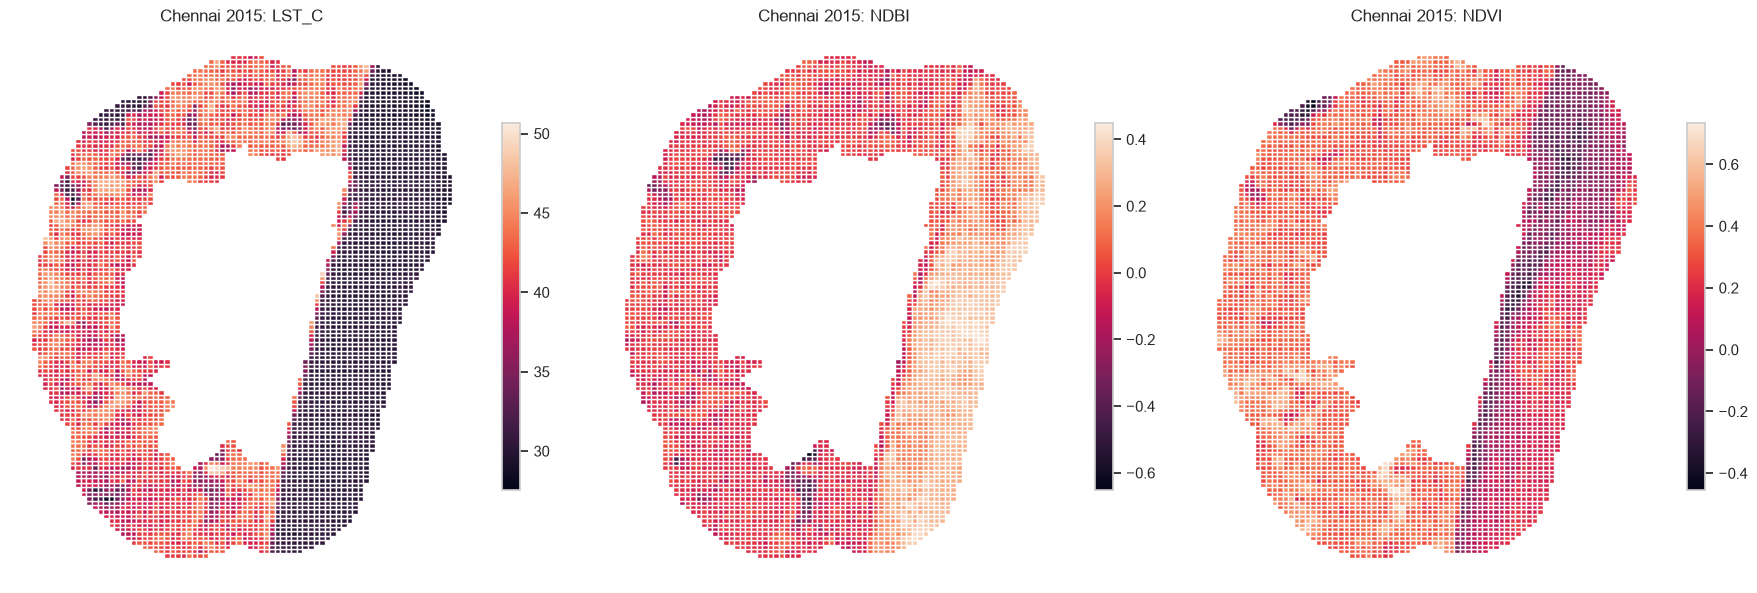

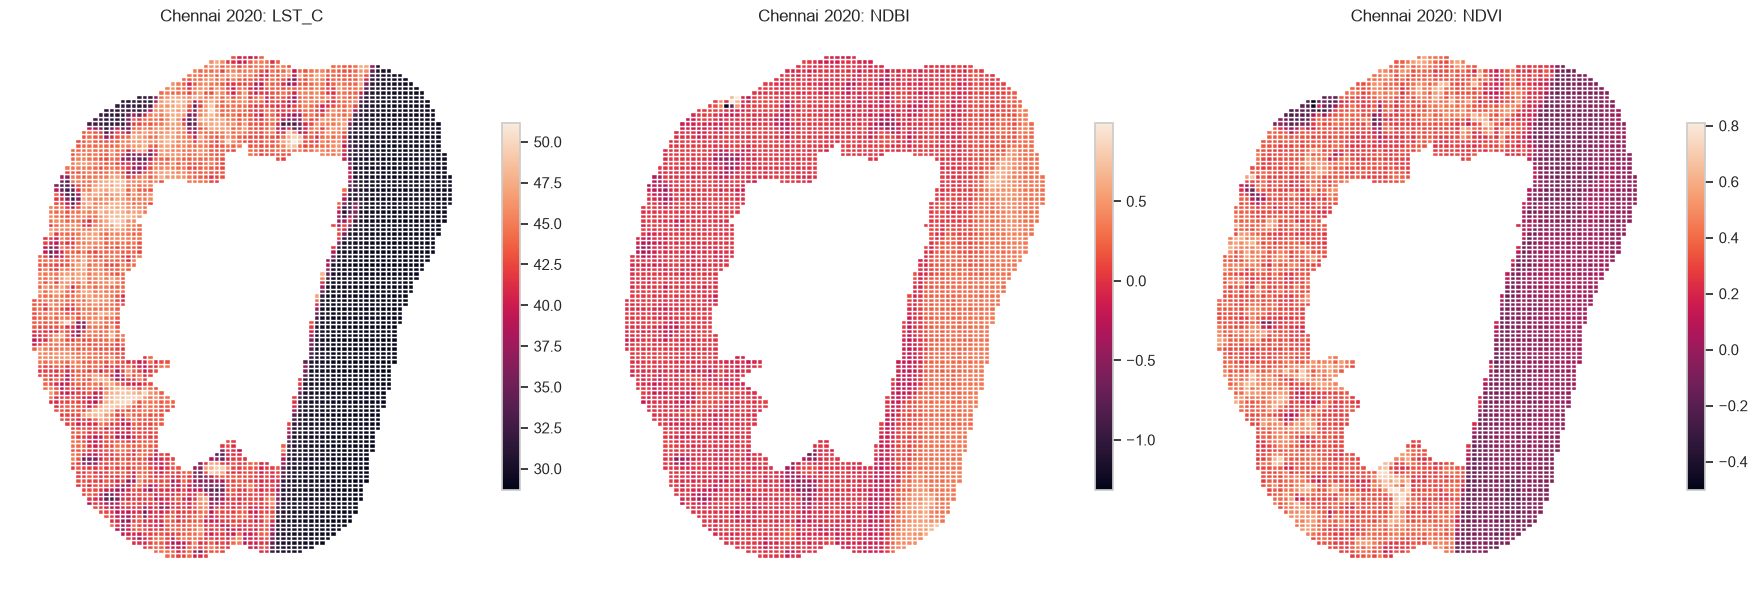

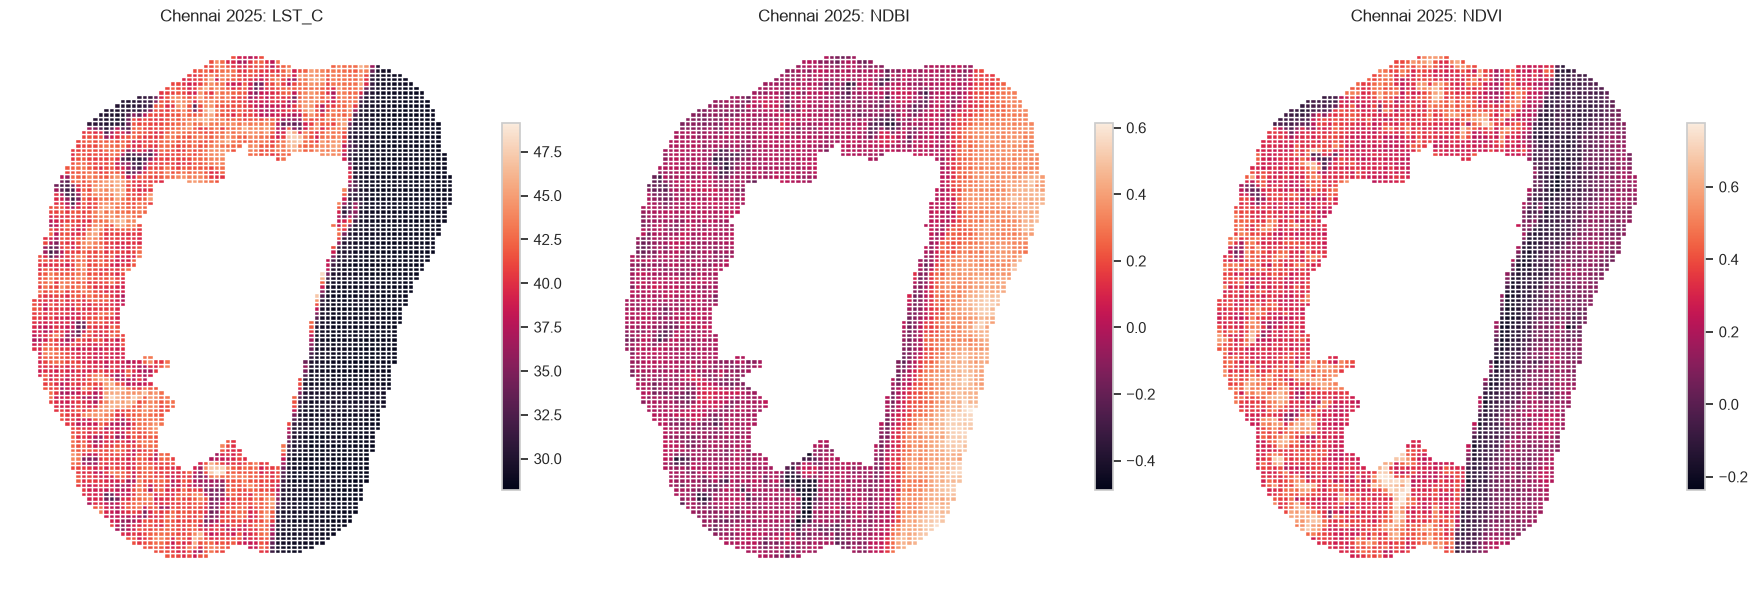

In [8]:

import geopandas as gpd
from pathlib import Path

# Change this path to your actual 300 m grid shapefile
SHAPEFILE_PATH = PROJECT_DIR / "grids" / f"{CITY}_Grid_300m.shp"

if not SHAPEFILE_PATH.exists():
    print(f"Shapefile not found: {SHAPEFILE_PATH}")
else:
    grid = gpd.read_file(SHAPEFILE_PATH)

    print("Grid columns:", grid.columns.tolist())
    print("Grid CRS:", grid.crs)
    print("Number of grid cells:", len(grid))

    if "grid_id" not in grid.columns:
        raise ValueError(
            "The shapefile has no grid_id column. "
            "Check its column names and identify the matching grid ID field."
        )

    grid["grid_id"] = grid["grid_id"].astype(str)
    data["grid_id"] = data["grid_id"].astype(str)

    if grid.crs is None:
        raise ValueError("The shapefile has no CRS defined.")

    grid = grid.to_crs("EPSG:4326")

    for year in MAP_YEARS:
        year_data = data.loc[
            data["year"] == year,
            ["grid_id"] + VARIABLES
        ]

        joined = grid.merge(
            year_data,
            on="grid_id",
            how="left",
            validate="one_to_one"
        )

        fig, axes = plt.subplots(1, 3, figsize=(18, 6))

        for ax, variable in zip(axes, VARIABLES):
            joined.plot(
                column=variable,
                ax=ax,
                legend=True,
                missing_kwds={
                    "color": "lightgrey",
                    "label": "No data"
                },
                legend_kwds={"shrink": 0.65}
            )
            ax.set_title(f"{CITY} {year}: {variable.upper()}")
            ax.set_axis_off()

        plt.tight_layout()
        plt.savefig(
            OUTPUT_DIR / f"map_{CITY}_{year}.png",
            dpi=200,
            bbox_inches="tight"
        )
        plt.show()
